# 02 — Outcomes Analysis
Answers the 10 key questions in the brief using `data/cleaned_admissions.csv` (built by notebook 01).

Every rate is shown with its sample size **n**, and the important comparisons get a statistical test, so we don't read too much into small groups.
* **Chi-square test of independence**: are two categories (e.g. diagnosis and readmission) related?
* **Kruskal–Wallis / ANOVA**: do average values (e.g. length of stay) differ between groups?
* **Mann–Whitney U**: do two groups differ (e.g. ICU vs General cost per day)?
* **Binomial test / funnel plot**: is a doctor's readmission rate unusually high given how few patients they saw?

Rule used throughout: **p < 0.05 = statistically significant**.

In [1]:
import pandas as pd, numpy as np, json
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

BLUE, GREY, RED = '#2a78d6', '#52514e', '#d03b3b'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c9c8c2',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.labelcolor': GREY, 'xtick.color': GREY, 'ytick.color': GREY,
    'font.size': 10, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})
IMG = '../docs/images/'
df = pd.read_csv('../data/cleaned_admissions.csv', parse_dates=['admission_date', 'discharge_date'])
df['age_group'] = pd.Categorical(df.age_group, ['Child', 'Young Adult', 'Adult', 'Senior'], ordered=True)
R = {}   # collects headline numbers for docs/key_findings.md

def rate_table(by, flag, label):
    t = df.groupby(by, observed=True).agg(n=('admission_id', 'count'), events=(flag, 'sum'))
    t[label] = (t.events / t.n * 100).round(1)
    return t.sort_values(label, ascending=False)

def chi2(a, b):
    ct = pd.crosstab(df[a], df[b])
    chi, p, dof, exp = stats.chi2_contingency(ct)
    n = ct.values.sum(); v = np.sqrt(chi / (n * (min(ct.shape) - 1)))
    print(f'Chi-square {a} x {b}: chi2 = {chi:.2f}, dof = {dof}, p = {p:.3f}, Cramer\'s V = {v:.2f}'
          + ('  -> SIGNIFICANT' if p < 0.05 else '  -> not significant'))
    if (exp < 5).mean() > 0.2: print('  note: >20% of expected counts < 5, treat with caution')
    return round(chi, 2), round(p, 3), round(v, 2)

## Q1. Overall 30-day readmission rate

In [2]:
n, k = len(df), df.readmitted_within_30_days.sum()
lo, hi = proportion_confint(k, n, method='wilson')
print(f'{k} of {n} admissions readmitted within 30 days = {k/n*100:.1f}%  (95% CI {lo*100:.1f}% to {hi*100:.1f}%)')
R['readmit_rate'] = round(k / n * 100, 1); R['readmit_ci'] = [round(lo * 100, 1), round(hi * 100, 1)]

109 of 200 admissions readmitted within 30 days = 54.5%  (95% CI 47.6% to 61.3%)


**54.5%** is extremely high. Published 30-day readmission rates are usually in the 10–20% range. Either the flag means something broader than "unplanned readmission" (e.g. any follow-up visit), or this training data was randomly generated. **This should be confirmed with the data owner before anyone acts on it.**

### Readmission trend over time (time-series)

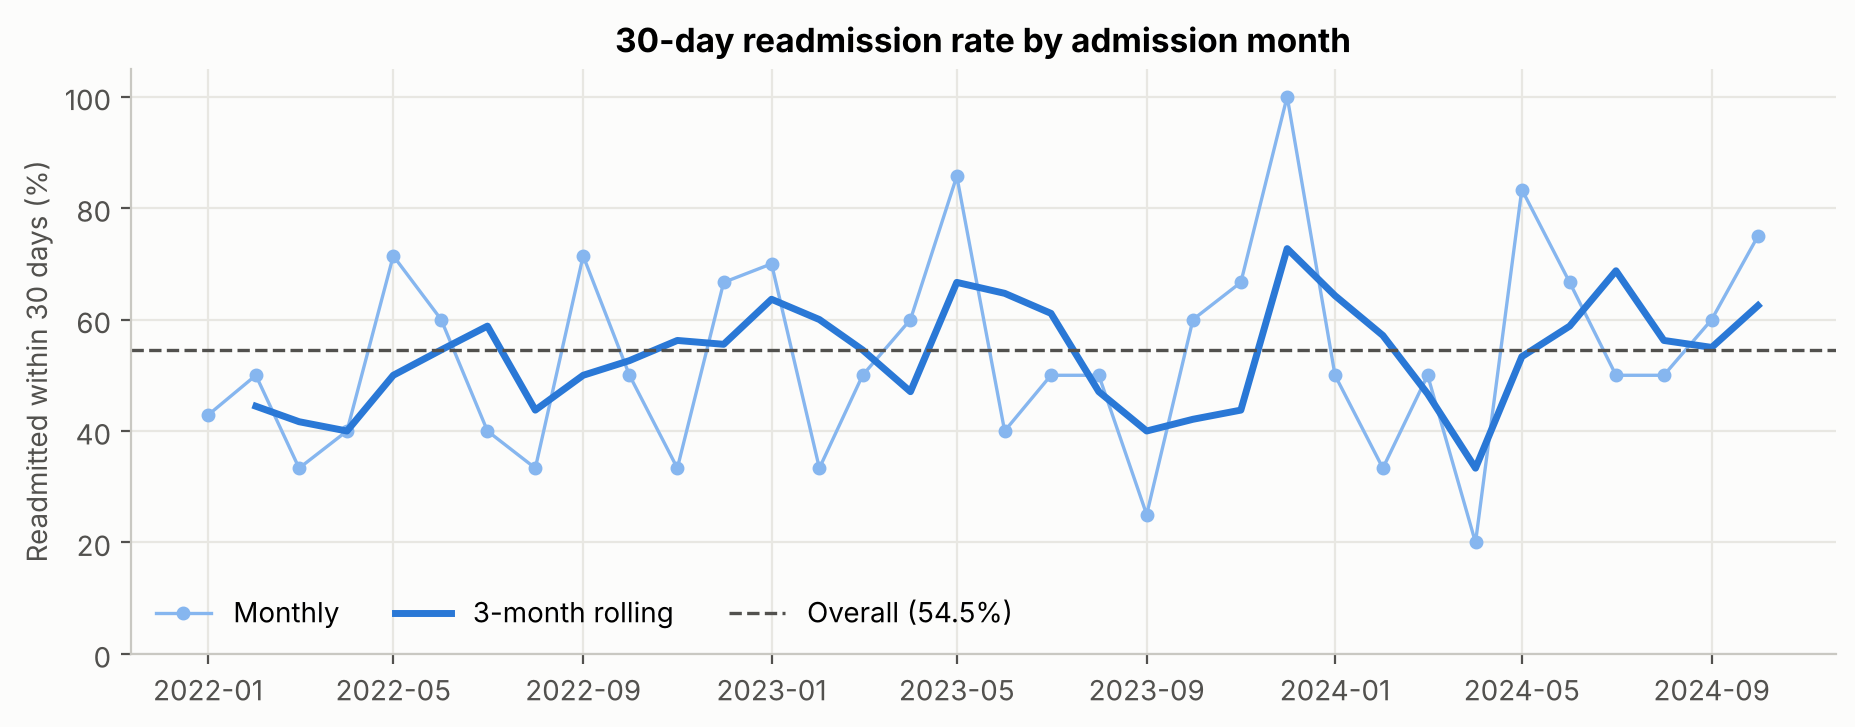

admission_quarter  2022Q1  2022Q2  2022Q3  2022Q4  2023Q1  2023Q2  2023Q3  \
n                    12.0    22.0    18.0    18.0    22.0    17.0    20.0   
r                     5.0    12.0     9.0    10.0    12.0    11.0     8.0   
rate_%               41.7    54.5    50.0    55.6    54.5    64.7    40.0   

admission_quarter  2023Q4  2024Q1  2024Q2  2024Q3  2024Q4  
n                    11.0    15.0    17.0    20.0     8.0  
r                     8.0     7.0    10.0    11.0     6.0  
rate_%               72.7    46.7    58.8    55.0    75.0  
Quarterly trend slope = +1.46 pts/quarter, p = 0.112


In [3]:
mon = df.groupby(df.admission_date.dt.to_period('M')).agg(n=('admission_id', 'count'), r=('readmitted_within_30_days', 'sum'))
mon = mon.reindex(pd.period_range(mon.index.min(), mon.index.max(), freq='M'), fill_value=0)
roll = mon.rolling(3, min_periods=2).sum()
mon['monthly_%'] = np.where(mon.n > 0, mon.r / mon.n * 100, np.nan)
mon['rolling_3m_%'] = roll.r / roll.n * 100
q = df.groupby('admission_quarter').agg(n=('admission_id', 'count'), r=('readmitted_within_30_days', 'sum'))
q['rate_%'] = (q.r / q.n * 100).round(1)

fig, ax = plt.subplots(figsize=(11, 3.8))
x = mon.index.to_timestamp()
ax.plot(x, mon['monthly_%'], color='#86b6ef', lw=1.2, marker='o', ms=4, label='Monthly')
ax.plot(x, mon['rolling_3m_%'], color=BLUE, lw=2.5, label='3-month rolling')
ax.axhline(R['readmit_rate'], color=GREY, ls='--', lw=1.2, label=f"Overall ({R['readmit_rate']}%)")
ax.set_ylim(0, 105); ax.set_ylabel('Readmitted within 30 days (%)'); ax.set_title('30-day readmission rate by admission month')
ax.legend(frameon=False, ncol=3, loc='lower left')
plt.savefig(IMG + 'readmission_trend.png'); plt.show()
slope = stats.linregress(np.arange(len(q)), q['rate_%'])
print(q.T); print(f'Quarterly trend slope = {slope.slope:+.2f} pts/quarter, p = {slope.pvalue:.3f}')
R['readmit_trend'] = {'slope_per_q': round(slope.slope, 2), 'p': round(slope.pvalue, 3),
                      'max_q': q['rate_%'].idxmax(), 'max_q_rate': float(q['rate_%'].max()),
                      'min_q': q['rate_%'].idxmin(), 'min_q_rate': float(q['rate_%'].min())}

## Q2. Which diagnosis has the highest readmission rate?

                    n  events  readmission_%
primary_diagnosis                           
Malaria            18      12           66.7
Typhoid            22      14           63.6
Diabetes           23      14           60.9
Appendicitis       15       9           60.0
Pneumonia          24      14           58.3
Anaemia            20      10           50.0
Fracture           24      12           50.0
HIV/AIDS           24      12           50.0
Hypertension       15       6           40.0
Tuberculosis       15       6           40.0
Chi-square primary_diagnosis x readmitted_within_30_days: chi2 = 5.62, dof = 9, p = 0.778, Cramer's V = 0.17  -> not significant


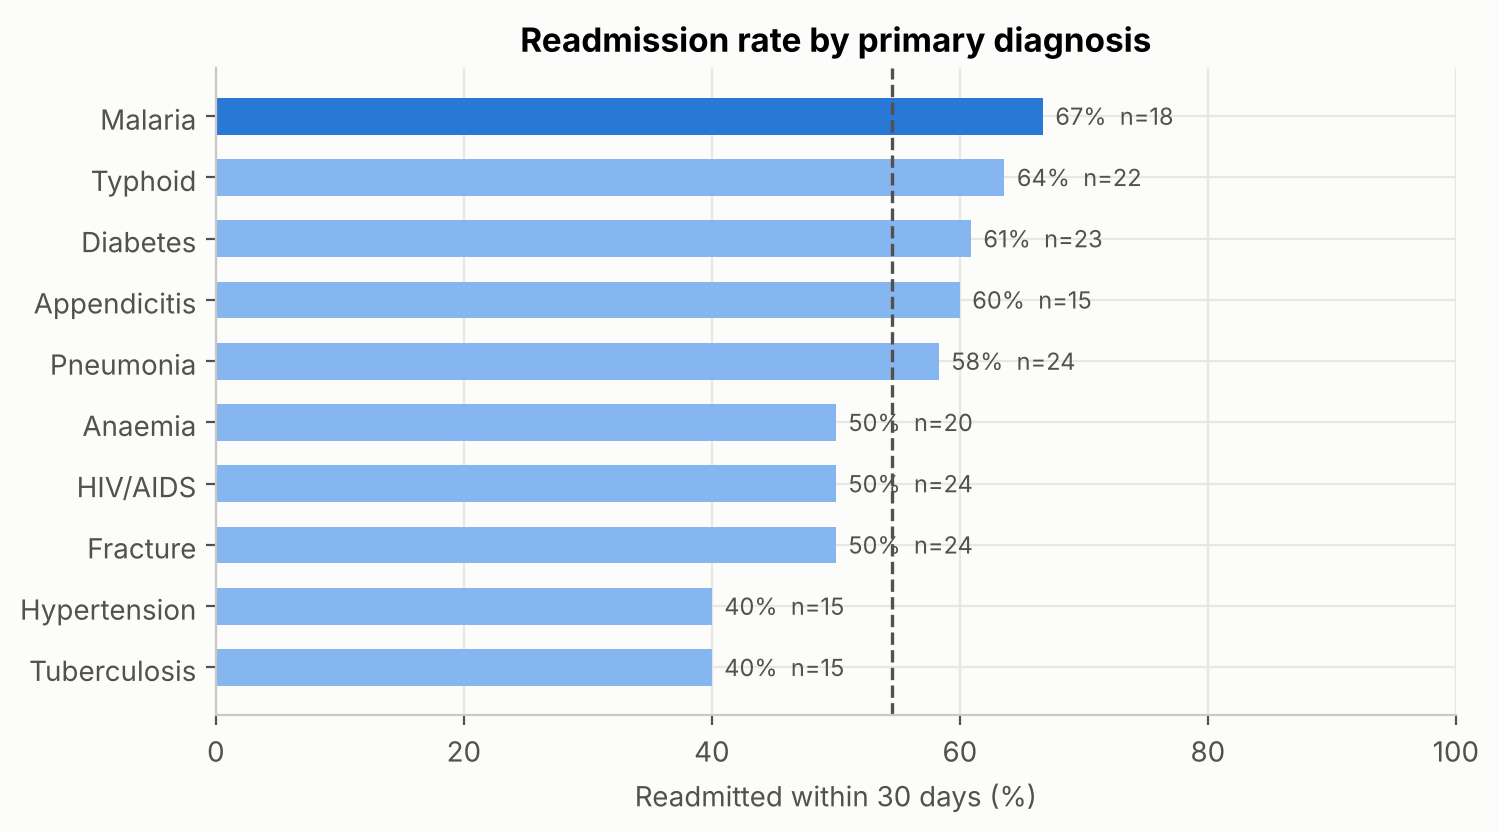

In [4]:
dx = rate_table('primary_diagnosis', 'readmitted_within_30_days', 'readmission_%')
print(dx)
R['dx_readmit'] = dx.reset_index().to_dict('records')
R['chi_dx_readmit'] = chi2('primary_diagnosis', 'readmitted_within_30_days')

fig, ax = plt.subplots(figsize=(8, 4.2))
d = dx.sort_values('readmission_%')
ax.barh(d.index, d['readmission_%'], color=[BLUE if i == d.index[-1] else '#86b6ef' for i in d.index], height=0.6)
ax.axvline(R['readmit_rate'], color=GREY, ls='--', lw=1.2)
for i, (v, n) in enumerate(zip(d['readmission_%'], d.n)): ax.text(v + 1, i, f'{v:.0f}%  n={n}', va='center', fontsize=8.5, color=GREY)
ax.set_xlim(0, 100); ax.set_xlabel('Readmitted within 30 days (%)'); ax.set_title('Readmission rate by primary diagnosis')
plt.savefig(IMG + 'readmission_by_diagnosis.png'); plt.show()

**Clinical hypothesis tested:** *"Readmission risk depends on the primary diagnosis."*
The chi-square result above tells us whether the differences between diagnoses are bigger than chance would produce. See the printed p-value: if it is above 0.05, we **cannot reject** the idea that every diagnosis carries the same readmission risk. The top diagnosis is still worth monitoring, but the ranking should not be treated as proof.

**Why might a chronic condition top the list?** Diseases such as diabetes, HIV/AIDS, TB and hypertension need ongoing medication and follow-up after discharge. Gaps in drug supply, cost (most patients here pay out of pocket or via NHIS), and weak follow-up make relapse and return visits more likely.

## Q3. Does length of stay differ between insurance types?

                count  mean  median   std
insurance_type                           
HMO                49  26.0    26.0  14.1
NHIS               52  25.6    25.5  12.5
Private            43  21.7    19.0  14.3
Out-of-Pocket      56  19.6    15.5  14.1
One-way ANOVA: F = 2.67, p = 0.049
Kruskal-Wallis: H = 7.53, p = 0.057


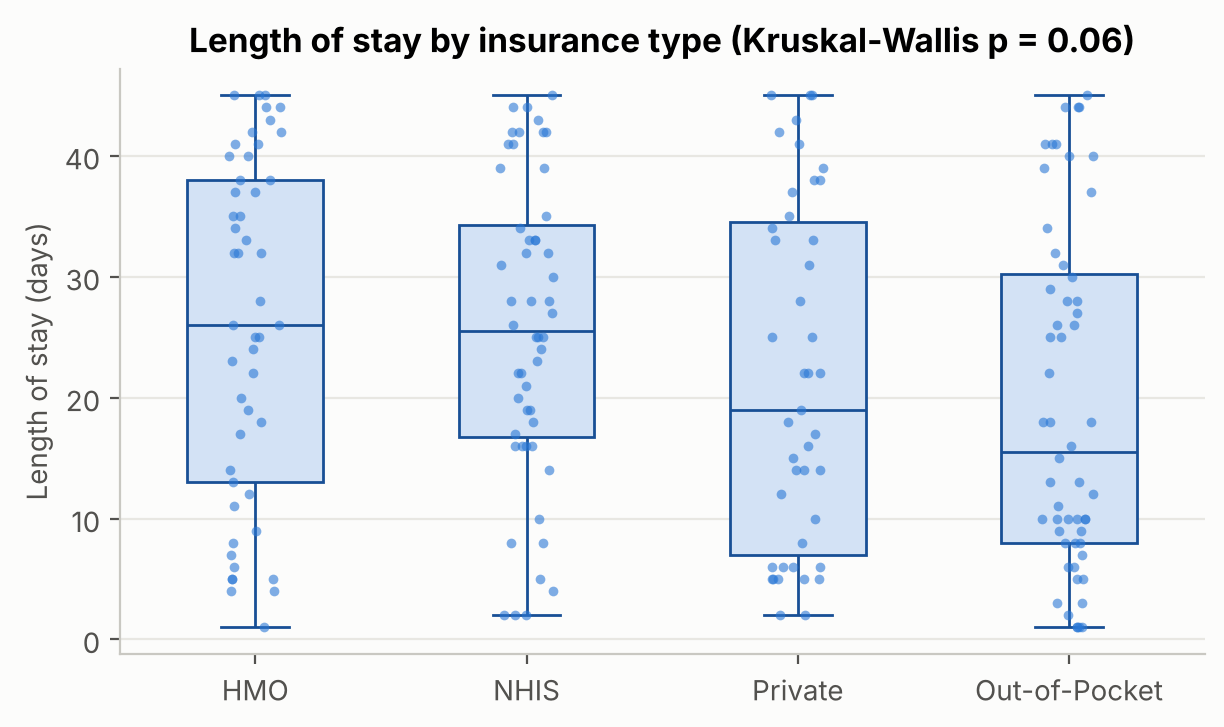

In [5]:
ins = df.groupby('insurance_type').length_of_stay_days.agg(['count', 'mean', 'median', 'std']).round(1).sort_values('mean', ascending=False)
print(ins)
groups = [g.length_of_stay_days.values for _, g in df.groupby('insurance_type')]
f = stats.f_oneway(*groups); kw = stats.kruskal(*groups)
print(f'One-way ANOVA: F = {f.statistic:.2f}, p = {f.pvalue:.3f}')
print(f'Kruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}')
R['los_insurance'] = ins.reset_index().to_dict('records'); R['los_ins_p'] = [round(f.pvalue, 3), round(kw.pvalue, 3)]

fig, ax = plt.subplots(figsize=(7, 3.8))
order = ins.index.tolist()
sns.boxplot(data=df, x='insurance_type', y='length_of_stay_days', order=order, color='#cde2fb', linecolor='#184f95', width=0.5, ax=ax)
sns.stripplot(data=df, x='insurance_type', y='length_of_stay_days', order=order, color=BLUE, size=3.5, alpha=0.6, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('Length of stay (days)'); ax.set_title(f'Length of stay by insurance type (Kruskal-Wallis p = {kw.pvalue:.2f})')
plt.savefig(IMG + 'los_by_insurance.png'); plt.show()

### Readmission rate by insurance type (required SQL query, tested here)

In [6]:
ri = rate_table('insurance_type', 'readmitted_within_30_days', 'readmission_%')
print(ri)
R['ins_readmit'] = ri.reset_index().to_dict('records')
R['chi_ins_readmit'] = chi2('insurance_type', 'readmitted_within_30_days')

                 n  events  readmission_%
insurance_type                           
NHIS            52      34           65.4
Out-of-Pocket   56      31           55.4
Private         43      22           51.2
HMO             49      22           44.9
Chi-square insurance_type x readmitted_within_30_days: chi2 = 4.52, dof = 3, p = 0.211, Cramer's V = 0.15  -> not significant


## Q4. Which hospital has the highest / lowest patient satisfaction?
**`satisfaction_score` is not in the supplied dataset**, so this question cannot be answered as written, and no scores were invented.
As a stand-in, the hospital scorecard ranks facilities on the outcome measures that *are* available. **Recovery rate** (share discharged as Recovered) is the closest proxy for a good patient experience. Hospitals with fewer than 8 admissions are flagged as low-volume.

In [7]:
h = df.groupby('hospital_id').agg(admissions=('admission_id', 'count'),
        avg_los=('length_of_stay_days', 'mean'),
        readmission_pct=('readmitted_within_30_days', 'mean'),
        mortality_pct=('died', 'mean'),
        recovery_pct=('discharge_outcome', lambda s: (s == 'Recovered').mean()),
        avg_cost=('total_cost_ngn', 'mean'),
        billed=('total_cost_ngn', 'sum'), paid=('amount_paid_ngn', 'sum'))
h['collection_pct'] = h.paid / h.billed   # pooled, matches SQL and the Excel scorecard
h = h.drop(columns=['billed', 'paid'])
for c in ['readmission_pct', 'mortality_pct', 'recovery_pct', 'collection_pct']: h[c] = (h[c] * 100).round(1)
h['avg_los'] = h.avg_los.round(1); h['avg_cost'] = h.avg_cost.round(0)
h['low_volume'] = h.admissions < 8
h = h.sort_values('recovery_pct', ascending=False)
print(h)
ok = h[~h.low_volume]
R['hosp_best_recovery'] = [ok.recovery_pct.idxmax(), float(ok.recovery_pct.max()), int(ok.loc[ok.recovery_pct.idxmax(), 'admissions'])]
R['hosp_worst_recovery'] = [ok.recovery_pct.idxmin(), float(ok.recovery_pct.min()), int(ok.loc[ok.recovery_pct.idxmin(), 'admissions'])]
R['hosp_best_mort'] = [ok.mortality_pct.idxmin(), float(ok.mortality_pct.min())]
R['hosp_worst_mort'] = [ok.mortality_pct.idxmax(), float(ok.mortality_pct.max())]
print('\nAmong hospitals with >= 8 admissions:', R['hosp_best_recovery'], R['hosp_worst_recovery'])
h.to_csv('../data/hospital_summary.csv')

             admissions  avg_los  readmission_pct  mortality_pct  \
hospital_id                                                        
HOSP002               7     15.6             57.1            0.0   
HOSP013              16     23.9             43.8           18.8   
HOSP016              11     22.6             27.3           27.3   
HOSP005              18     25.7             55.6           16.7   
HOSP011              12     25.6             66.7            8.3   
HOSP010               7     23.6             57.1           28.6   
HOSP019               7     19.3             71.4            0.0   
HOSP008              11     18.2             90.9           36.4   
HOSP012              13     29.4             61.5            0.0   
HOSP018               9     26.0             44.4           33.3   
HOSP001               9     12.2             55.6           33.3   
HOSP015               9     28.3             66.7           22.2   
HOSP006               5     21.2             60.

## Q5. Mortality rate by department — where is the most room for improvement?

             n  events  mortality_%  expected_deaths  excess_deaths
department                                                         
Paediatric  40      14         35.0              9.0            5.0
ICU         42      10         23.8              9.5            0.5
Maternity   30       7         23.3              6.8            0.2
General     51       9         17.6             11.5           -2.5
Private     37       5         13.5              8.3           -3.3
Chi-square department x died: chi2 = 6.04, dof = 4, p = 0.196, Cramer's V = 0.17  -> not significant


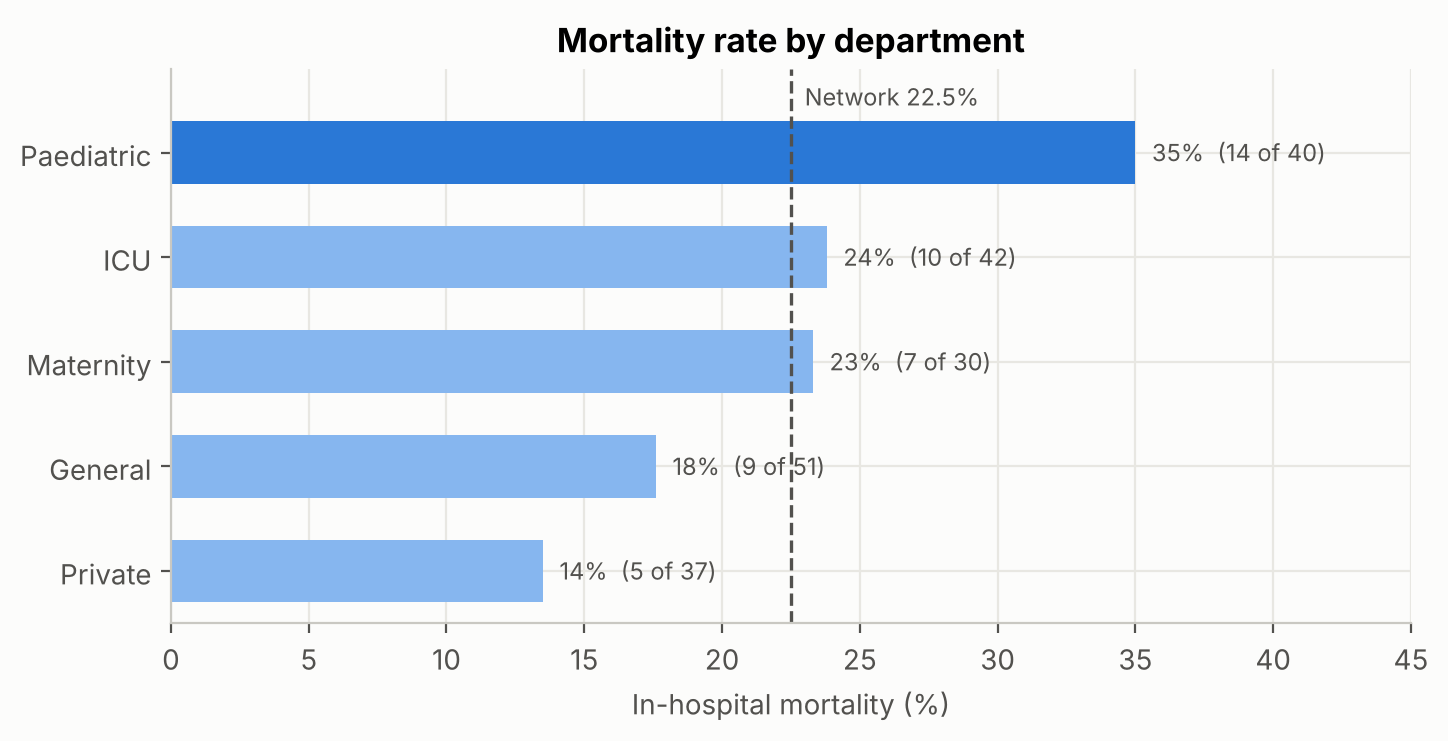


Discharge outcome mix by department (%):
discharge_outcome  Died  Left Against Advice  Recovered  Referred
department                                                       
General            17.6                 17.6       23.5      41.2
ICU                23.8                 33.3       23.8      19.0
Maternity          23.3                 26.7       26.7      23.3
Paediatric         35.0                 15.0       22.5      27.5
Private            13.5                 32.4       32.4      21.6


In [8]:
dep = rate_table('department', 'died', 'mortality_%')
net = df.died.mean()
dep['expected_deaths'] = (dep.n * net).round(1)
dep['excess_deaths'] = (dep.events - dep.expected_deaths).round(1)
print(dep)
R['dept_mort'] = dep.reset_index().to_dict('records')
R['mort_rate'] = round(net * 100, 1)
R['chi_dept_mort'] = chi2('department', 'died')

fig, ax = plt.subplots(figsize=(8, 3.6))
d = dep.sort_values('mortality_%')
ax.barh(d.index, d['mortality_%'], color=[BLUE if i == d.index[-1] else '#86b6ef' for i in d.index], height=0.6)
ax.axvline(net * 100, color=GREY, ls='--', lw=1.2); ax.text(net * 100 + 0.5, 4.45, f'Network {net*100:.1f}%', fontsize=8.5, color=GREY)
for i, (v, n, e) in enumerate(zip(d['mortality_%'], d.n, d.events)): ax.text(v + 0.6, i, f'{v:.0f}%  ({e} of {n})', va='center', fontsize=8.5, color=GREY)
ax.set_ylim(-0.5, 4.8); ax.set_xlim(0, 45); ax.set_xlabel('In-hospital mortality (%)'); ax.set_title('Mortality rate by department')
plt.savefig(IMG + 'mortality_by_department.png'); plt.show()

print('\nDischarge outcome mix by department (%):')
print((pd.crosstab(df.department, df.discharge_outcome, normalize='index') * 100).round(1))

The department with the highest mortality **and** the most deaths above what the network-average rate would predict (`excess_deaths`) has the most room for improvement. Note that ICU mortality is *expected* to be higher because it receives the sickest patients, so a high ICU rate should be compared with ICU benchmarks, not with the general ward.

## Q6. Are weekend admissions linked to discharge outcomes? (the 'weekend effect')

In [9]:
wk = pd.crosstab(df.weekend_admission.map({0: 'Weekday', 1: 'Weekend'}), df.discharge_outcome, margins=True)
print(wk); print()
print((pd.crosstab(df.weekend_admission.map({0: 'Weekday', 1: 'Weekend'}), df.discharge_outcome, normalize='index') * 100).round(1))
R['chi_weekend_outcome'] = chi2('weekend_admission', 'discharge_outcome')
R['chi_weekend_died'] = chi2('weekend_admission', 'died')
w = df.groupby('weekend_admission').agg(n=('admission_id', 'count'), mort=('died', 'mean'), readm=('readmitted_within_30_days', 'mean'))
R['weekend'] = {'n_weekend': int(w.loc[1, 'n']), 'n_weekday': int(w.loc[0, 'n']),
                'mort_weekend': round(w.loc[1, 'mort'] * 100, 1), 'mort_weekday': round(w.loc[0, 'mort'] * 100, 1)}
print(R['weekend'])

discharge_outcome  Died  Left Against Advice  Recovered  Referred  All
weekend_admission                                                     
Weekday              37                   28         36        35  136
Weekend               8                   21         15        20   64
All                  45                   49         51        55  200

discharge_outcome  Died  Left Against Advice  Recovered  Referred
weekend_admission                                                
Weekday            27.2                 20.6       26.5      25.7
Weekend            12.5                 32.8       23.4      31.2
Chi-square weekend_admission x discharge_outcome: chi2 = 7.48, dof = 3, p = 0.058, Cramer's V = 0.19  -> not significant


Chi-square weekend_admission x died: chi2 = 4.59, dof = 1, p = 0.032, Cramer's V = 0.15  -> SIGNIFICANT
{'n_weekend': 64, 'n_weekday': 136, 'mort_weekend': np.float64(12.5), 'mort_weekday': np.float64(27.2)}


## Q7. Average cost per patient day: ICU vs General ward

Two ways to measure it, both shown:
* **Mean of per-admission cost/day**: the average patient's daily cost (sensitive to very short, expensive stays).
* **Pooled**: total ₦ billed ÷ total bed-days. This is what finance teams usually mean by "cost per patient day".

In [10]:
cpd = df.groupby('bed_type').agg(admissions=('admission_id', 'count'),
        mean_cost_per_day=('cost_per_day', 'mean'), median_cost_per_day=('cost_per_day', 'median'),
        total_cost=('total_cost_ngn', 'sum'), bed_days=('length_of_stay_days', 'sum'))
cpd['pooled_cost_per_day'] = cpd.total_cost / cpd.bed_days
cpd = cpd.round(0)
print(cpd[['admissions', 'mean_cost_per_day', 'median_cost_per_day', 'pooled_cost_per_day']])
mw = stats.mannwhitneyu(df.loc[df.bed_type == 'ICU', 'cost_per_day'], df.loc[df.bed_type == 'General', 'cost_per_day'])
print(f'\nMann-Whitney ICU vs General cost/day: U = {mw.statistic:.0f}, p = {mw.pvalue:.3f}')
R['cpd'] = cpd.reset_index()[['bed_type', 'admissions', 'mean_cost_per_day', 'median_cost_per_day', 'pooled_cost_per_day']].to_dict('records')
R['cpd_p'] = round(mw.pvalue, 3)

          admissions  mean_cost_per_day  median_cost_per_day  \
bed_type                                                       
General          121            40758.0              16821.0   
ICU               42            41980.0              23874.0   
Private           37            32280.0              18152.0   

          pooled_cost_per_day  
bed_type                       
General               17799.0  
ICU                   20529.0  
Private               18141.0  

Mann-Whitney ICU vs General cost/day: U = 2784, p = 0.357


Mean cost/day is much higher than pooled cost/day because a few 1–3 day stays have bills of ₦300k+, which gives huge per-day figures. The medians and pooled figures are the safer numbers to quote.

## Q8. Which age group has the most admissions, and what are their main diagnoses?

age_group
Child          35
Young Adult    42
Adult          48
Senior         75
Name: count, dtype: int64 

Top diagnoses for Seniors:
primary_diagnosis
HIV/AIDS     13
Fracture     10
Pneumonia     9
Malaria       7
Anaemia       7
Name: count, dtype: int64


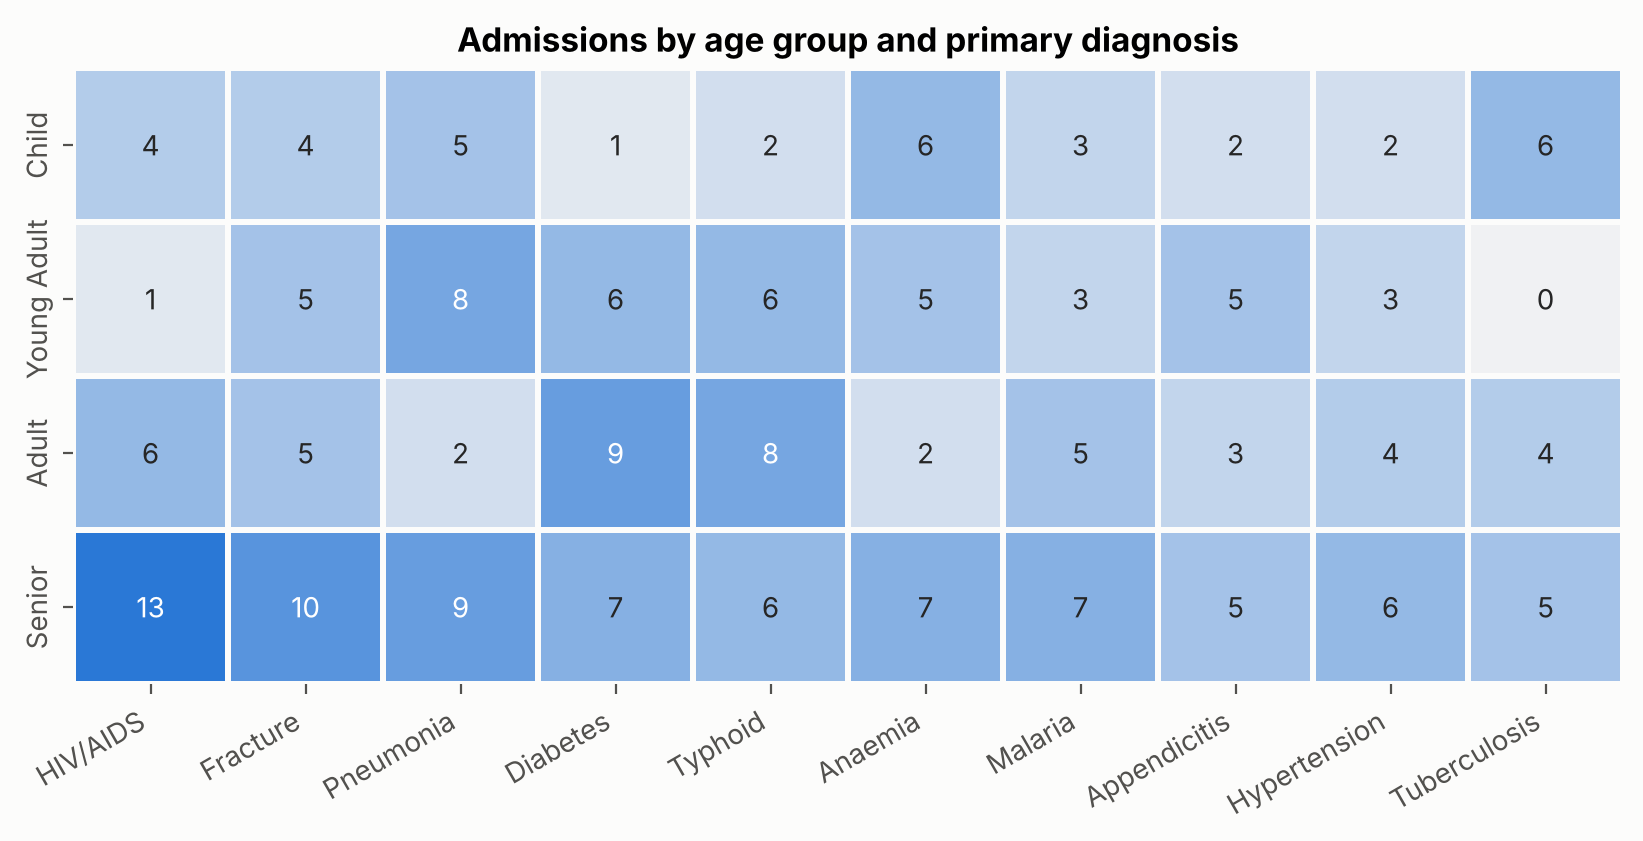

In [11]:
ag = df.age_group.value_counts().sort_index()
print(ag, '\n')
top = df.age_group.value_counts().idxmax()
tdx = df[df.age_group == top].primary_diagnosis.value_counts()
print(f'Top diagnoses for {top}s:'); print(tdx.head(5))
R['age_counts'] = {str(k): int(v) for k, v in ag.items()}
R['top_age'] = str(top); R['top_age_dx'] = tdx.head(5).to_dict()

fig, ax = plt.subplots(figsize=(10, 4))
ct = pd.crosstab(df.primary_diagnosis, df.age_group)
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]
sns.heatmap(ct.T, annot=True, fmt='d', cmap=sns.light_palette(BLUE, as_cmap=True), linewidths=2, linecolor='#fcfcfb', cbar=False, ax=ax)
ax.set_title('Admissions by age group and primary diagnosis'); ax.set_xlabel(''); ax.set_ylabel('')
plt.xticks(rotation=30, ha='right'); plt.savefig(IMG + 'age_by_diagnosis.png'); plt.show()

## Q9. Are certain doctors associated with higher readmission rates?
Doctors in this data work across several hospitals (avg 3.6 hospitals each), so each doctor is benchmarked against **their own expected rate**: the average readmission rate of the hospitals where they treated patients, weighted by their admissions there. *(This is the brief's "subquery: doctors above the hospital average", adapted for doctors who move between facilities.)*

Doctors see only 1–9 patients each. A doctor with 3 of 3 readmitted shows 100% but may just be unlucky. A **funnel plot** handles this: the control limits are wide for small n and narrow for large n. Only doctors **outside the funnel** are statistically unusual.

In [12]:
hosp_rate = df.groupby('hospital_id').readmitted_within_30_days.mean()
df['hosp_expected'] = df.hospital_id.map(hosp_rate)
doc = df.groupby('attending_doctor_id').agg(n=('admission_id', 'count'),
        readmissions=('readmitted_within_30_days', 'sum'),
        expected_rate=('hosp_expected', 'mean'), hospitals=('hospital_id', 'nunique'))
doc['readmission_%'] = (doc.readmissions / doc.n * 100).round(1)
doc['expected_%'] = (doc.expected_rate * 100).round(1)
doc['gap_pts'] = (doc['readmission_%'] - doc['expected_%']).round(1)
p0 = df.readmitted_within_30_days.mean()
doc['p_value_high'] = [stats.binomtest(int(r), int(n), p0, alternative='greater').pvalue for r, n in zip(doc.readmissions, doc.n)]
doc['above_expected'] = doc.gap_pts > 0
doc['flag'] = np.where((doc.p_value_high < 0.05), 'Statistically high', np.where(doc.above_expected & (doc.n >= 5), 'Above expected (watch)', ''))
doc = doc.drop(columns='expected_rate').sort_values(['gap_pts', 'n'], ascending=False)
print(f'Doctors above their expected rate: {doc.above_expected.sum()} of {len(doc)}')
print(doc.head(12))
doc.to_csv('../data/doctor_benchmark.csv')
R['doc_above'] = int(doc.above_expected.sum()); R['doc_total'] = len(doc)
R['doc_sig'] = doc[doc.flag == 'Statistically high'].reset_index()[['attending_doctor_id', 'n', 'readmissions', 'readmission_%', 'expected_%', 'p_value_high']].round(3).to_dict('records')
R['doc_watch'] = doc[doc.flag == 'Above expected (watch)'].reset_index()[['attending_doctor_id', 'n', 'readmissions', 'readmission_%', 'expected_%']].to_dict('records')

Doctors above their expected rate: 21 of 48
                     n  readmissions  hospitals  readmission_%  expected_%  \
attending_doctor_id                                                          
DR030                1             1          1          100.0        54.5   
DR027                4             4          4          100.0        54.6   
DR042                1             1          1          100.0        57.1   
DR011                8             7          8           87.5        49.5   
DR018                2             2          2          100.0        63.5   
DR023                4             4          4          100.0        65.6   
DR044                8             7          7           87.5        54.1   
DR013                4             3          4           75.0        47.7   
DR010                4             3          3           75.0        50.2   
DR006                5             4          3           80.0        56.4   
DR045               

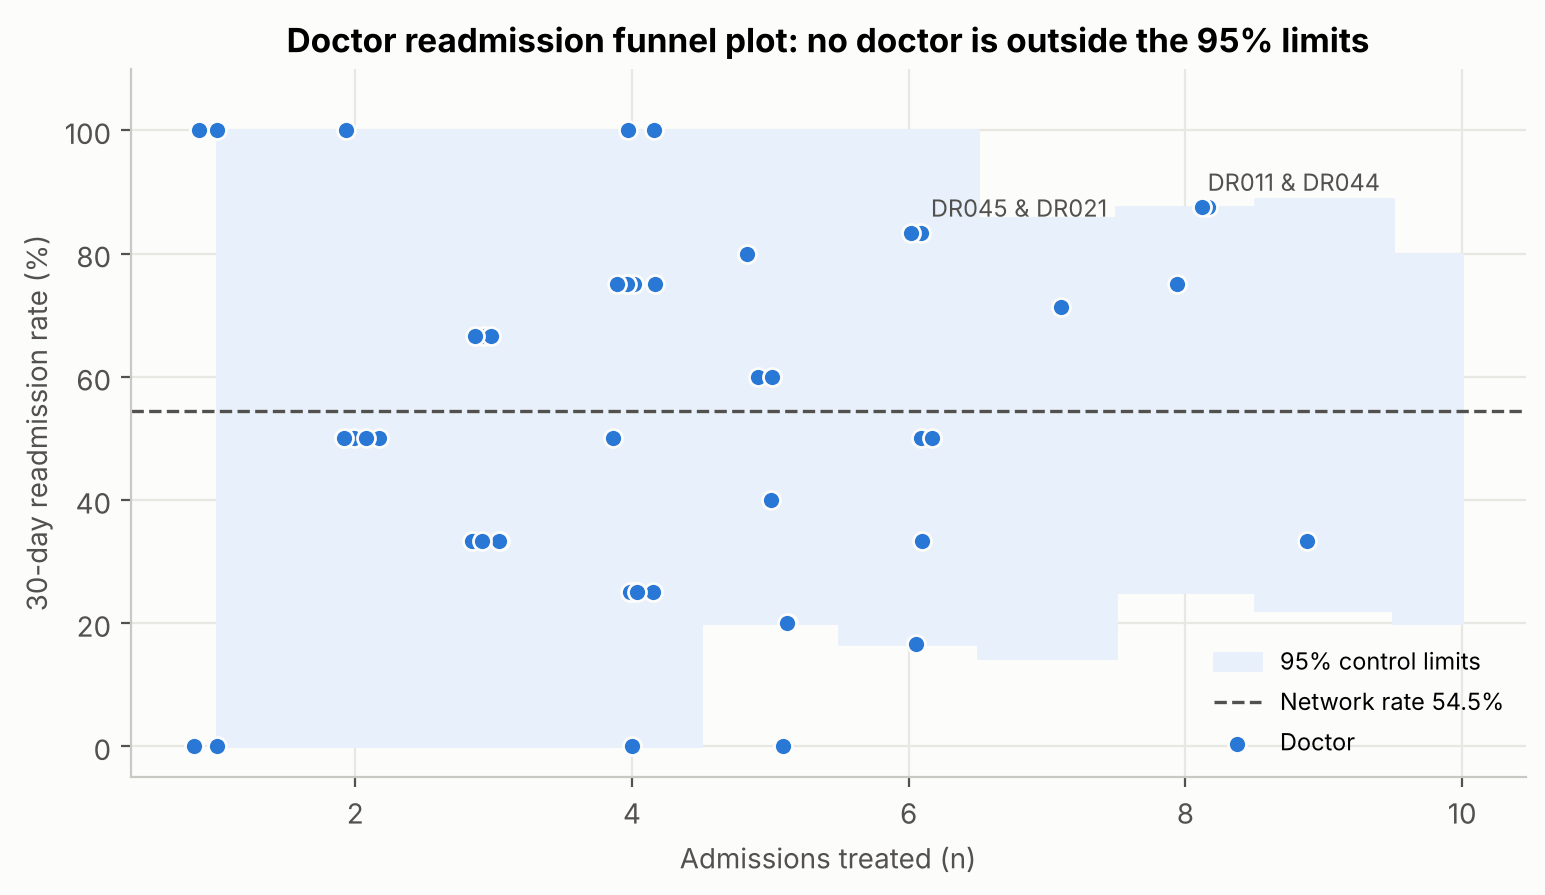

In [13]:
# Funnel plot
ns = np.arange(1, doc.n.max() + 2)
up95 = [stats.binom.ppf(0.975, n, p0) / n * 100 for n in ns]; lo95 = [stats.binom.ppf(0.025, n, p0) / n * 100 for n in ns]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.fill_between(ns, lo95, up95, step='mid', color='#e8f0fb', label='95% control limits')
ax.axhline(p0 * 100, color=GREY, ls='--', lw=1.2, label=f'Network rate {p0*100:.1f}%')
jit = np.random.default_rng(1).uniform(-0.18, 0.18, len(doc))
sig = doc.flag == 'Statistically high'
ax.scatter(doc.n[~sig] + jit[~sig], doc['readmission_%'][~sig], s=42, color=BLUE, edgecolor='#fcfcfb', lw=1, label='Doctor', zorder=3)
if sig.any():
    ax.scatter(doc.n[sig] + jit[sig], doc['readmission_%'][sig], s=60, color=RED, edgecolor='#fcfcfb', lw=1, label='Outside funnel (high)', zorder=4)
# Label doctors sitting at the top edge of the funnel; doctors sharing a point get one combined label
edge = doc[sig | ((doc.n >= 6) & (doc['readmission_%'] >= 80))].reset_index()
for (n_, r_), g in edge.groupby(['n', 'readmission_%']):
    ax.annotate(' & '.join(g.attending_doctor_id), (n_, r_), xytext=(8, 6), textcoords='offset points', fontsize=8.5, color=GREY)
ax.set_xlabel('Admissions treated (n)'); ax.set_ylabel('30-day readmission rate (%)'); ax.set_ylim(-5, 110)
ax.set_title('Doctor readmission funnel plot: no doctor is outside the 95% limits'); ax.legend(frameon=False, fontsize=8.5, loc='lower right')
plt.savefig(IMG + 'doctor_funnel.png'); plt.show()

## Extra: financial picture by insurance type

In [14]:
fin = df.groupby('insurance_type').agg(admissions=('admission_id', 'count'), avg_bill=('total_cost_ngn', 'mean'),
        billed=('total_cost_ngn', 'sum'), paid=('amount_paid_ngn', 'sum'), outstanding_total=('outstanding_ngn', 'sum'))
fin['collection_pct'] = (fin.paid / fin.billed * 100).round(1)   # pooled: N collected / N billed
fin = fin.drop(columns=['billed', 'paid']); fin[['avg_bill', 'outstanding_total']] = fin[['avg_bill', 'outstanding_total']].round(0)
print(fin.sort_values('collection_pct'))
print(f"\nNetwork: billed N{df.total_cost_ngn.sum():,.0f}, collected N{df.amount_paid_ngn.sum():,.0f} "
      f"({df.amount_paid_ngn.sum()/df.total_cost_ngn.sum()*100:.1f}%), outstanding N{df.outstanding_ngn.sum():,.0f}")
R['fin'] = {'billed': round(df.total_cost_ngn.sum()), 'collected': round(df.amount_paid_ngn.sum()),
            'outstanding': round(df.outstanding_ngn.sum()), 'collection_pct': round(df.amount_paid_ngn.sum() / df.total_cost_ngn.sum() * 100, 1),
            'by_ins': fin.reset_index().to_dict('records')}
R['outcome_mix'] = (df.discharge_outcome.value_counts(normalize=True) * 100).round(1).to_dict()
R['avg_los'] = round(df.length_of_stay_days.mean(), 1); R['avg_cost'] = round(df.total_cost_ngn.mean())
R['lama_rate'] = round((df.discharge_outcome == 'Left Against Advice').mean() * 100, 1)

                admissions  avg_bill  outstanding_total  collection_pct
insurance_type                                                         
Private                 43  389786.0          5997206.0            64.2
HMO                     49  423137.0          7350536.0            64.5
NHIS                    52  484701.0          8200368.0            67.5
Out-of-Pocket           56  402896.0          7281021.0            67.7

Network: billed N85,261,129, collected N56,431,997 (66.2%), outstanding N28,829,132


## Save headline numbers

In [15]:
def conv(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
json.dump(R, open('../docs/analysis_results.json', 'w'), indent=2, default=conv)
print('saved docs/analysis_results.json')

saved docs/analysis_results.json


## Summary of statistical tests
| Hypothesis | Test | Result |
|---|---|---|
| Readmission depends on diagnosis | Chi-square | see Q2 output |
| Readmission depends on insurance type | Chi-square | see Q3 output |
| LOS differs by insurance type | ANOVA + Kruskal-Wallis | see Q3 output |
| Mortality differs by department | Chi-square | see Q5 output |
| Weekend admission affects outcome | Chi-square | see Q6 output |
| ICU cost/day differs from General | Mann-Whitney U | see Q7 output |
| Some doctors have unusually high readmissions | Binomial test + funnel plot | see Q9 output |

Write-up with interpretation: `docs/key_findings.md`.